# Notebook 6: Simulating nuclear fission
## 6.1) How the problem will be described

Lamarsh & Baratta, Introduction to Nuclear Engineering; Duderstadt & Hamilton, Nuclear Reactor Analysis (1976).
Bell & Glasstone, Nuclear Reactor Theory (1970)
Harris, The Theory of Branching Processes (1963)
Pázsit & Pál, Neutron Fluctuations (2008).

Notebook 5 showed that the mousetrap cascade is a population model: a firing trap is an individual that reproduces by firing others. Nuclear fission is the same structure, with **neutrons as offspring**. A fission emits $\nu$ neutrons. Each neutron travels some distance and then does one of three things:
- it lands on a fissile nucleus and causes a new fission, with probability $p_f$;
- it is absorbed without fission, by non-fissile material or by capture;
- it escapes through the boundary of the system (**leakage**).

The lattice states and parameters translate directly:

| Mousetrap | Population (Notebook 5) | Fission |
|---|---|---|
| $-1$ inert | unsuitable habitat | non-fissile material (absorbs neutrons) |
| $0$ armed | susceptible | fissile nucleus |
| $1$ firing | infected / reproducing | fission in this generation |
| $-2$ spent | recovered / dead | fission products |
| ball | offspring | neutron |
| $m$ attempts | offspring attempts | $\nu$ neutrons, random, $\bar\nu \approx 2.4$ for $^{235}\mathrm{U}$|
| $f_k$, $p_{\text{long}}$ | dispersal kernel | neutron flight-length distribution |
| $p_{\text{succ}}$ | success per attempt | $p_f = \sigma_f / (\sigma_f + \sigma_c)$ |
| $\kappa$ | offspring per individual | $\bar\nu\, p_f$ |
| $\rho\kappa$ | $R_0$ | $k_\infty = \rho\,\bar\nu\,p_f$, the multiplication factor |

A system is **critical** at $k = 1$, subcritical below and supercritical above. This is the same threshold as $\rho\kappa = 1$.

Three things change with respect to Notebook 5.

**1. No depletion.** A lattice cell represents a macroscopic piece of fuel, containing of order $10^{20}$ nuclei. Over the timescales studied here the fraction of nuclei that fission is negligible, so a cell can fission any number of times. The state of the lattice is therefore a **count field** $n(\mathbf{x}, t)$, the number of fissions in cell $\mathbf{x}$ in generation $t$, instead of the four states above. This is the limit $p_{\text{regen}} \to 1$ of Notebook 5, with re-arming instantaneous.

The consequence is that the process becomes **linear**: neutrons do not compete for fuel, so different chains do not interact. The locality effects of Notebooks 3–5 came from attempts landing on already-spent traps. They should vanish here, and mean-field theory should become exact in the mean. This is a testable prediction.

(The opposite regime, in which the fuel is consumed, describes an explosive assembly. Its yield fraction obeys the final-size equation $F = 1 - e^{-kF}$ of Notebook 3, and it is not studied further here.)

**2. Leakage.** In Notebooks 3–5 a ball that would leave the lattice was redirected onto a cell inside it. Here a neutron that leaves the lattice is lost. Even with $k_\infty > 1$, a system that is too small loses too many neutrons through its surface to ustain a chain. This is the origin of a **critical mass**.

**3. Delayed neutrons.** A fraction $\beta$ of the neutrons is not emitted at the fission. They come from the decay of fission products, after a delay of many generations. For ${}^{235}\mathrm{U}$, $\beta \approx 0.0065$, yet these neutrons are what makes a reactor controllable.

These lead to three questions:

1. **Initiation:** does a single fission start a divergent chain?
2. **Critical size:** how large must the system be for $k_{\text{eff}} = 1$?
3. **Kinetics and control:** how does the neutron population respond when $k$ is changed, and why do delayed neutrons matter?

Each question is answered by the lattice simulation and by a mean-field prediction.

**Initiation.** As in 5.3, the early chain is a Galton–Watson branching process. A fission emits $\nu \sim P(\nu)$ neutrons, and each one causes a new fission with probability $a = \rho\,p_f$. The offspring generating function is
$$
G(s) = \sum_{\nu} P(\nu)\,(1 - a + a s)^{\nu},
$$
and the probability $q$ that one fission starts a divergent chain solves
$$
1 - q = G(1 - q).
$$
In the Poisson limit this reduces to $q = 1 - e^{-k_\infty q}$, the same equation as in 5.3. The offspring variance is $a^2\,\mathrm{Var}(\nu) + \bar\nu\, a(1 - a)$. This is smaller than the Poisson variance $k_\infty$ because $\mathrm{Var}(\nu) \approx 1.2 < \bar\nu$, so the real $q$ should lie above the Poisson curve.

**Critical size.** Leakage reduces $k_\infty$ to an effective multiplication factor $k_{\text{eff}}(L)$. One-group diffusion theory gives, for a bare $L \times L$ square,
$$
k_{\text{eff}} = \frac{k_\infty}{1 + M^2 B^2}, \qquad B^2 = \frac{2\pi^2}{L^2}, \qquad M^2 = \frac{\langle r^2 \rangle}{4}. \tag{1}
$$
Here $B^2$ is the geometric buckling and $M^2$ is the migration area, set by the mean squared flight distance $\langle r^2\rangle$ of a neutron between its birth and the next fission. Setting $k_{\text{eff}} = 1$ gives the critical size
$$
L_c = \pi\sqrt{\frac{2M^2}{k_\infty - 1}} .
$$
Diffusion theory should fail when $L$ is comparable to the flight length. The exact mean-field value of $k_{\text{eff}}$ is the dominant eigenvalue of the **fission matrix** $K_{ij}$, the expected number of fissions in cell $j$ caused by one fission in cell $i$. It can be computed by power iteration, the same algorithm used by Monte Carlo reactor codes.

**Kinetics.** Let $n_t$ be the number of fissions in generation $t$, and let $C_t$ be the number of delayed neutrons still pending. If each pending neutron is released with probability $\lambda$ per generation, the mean-field map is
$$
\begin{aligned}
n_{t+1} &= k(1-\beta)\, n_t + \lambda\left(C_t + k\beta\, n_t\right) \\
C_{t+1} &= (1 - \lambda)\left(C_t + k\beta\, n_t\right)
\end{aligned}
$$
The system is still critical at exactly $k = 1$. It becomes **prompt critical** at $k(1-\beta) = 1$, where the prompt neutrons alone sustain the chain. For $1 < k < 1/(1-\beta)$ the growth rate is set by the slow delayed neutrons instead of the fast prompt ones, which is the regime in which reactors are operated. Real delays are of order $10^{5}$ generations, which is impossible to simulate, so toy values of $\beta$ and $\lambda$ are used. The structure of the result does not depend on them.



In [1]:
from Functions_final import distance_cells      
from Functions_final import final_history        

## 6.2) The fission model

The lattice function of Notebook 5, `regen_history`, is adapted in four ways (see 6.1):

1. **State.** A fixed `fuel` mask (fissile with probability $\rho$, otherwise inert) plus a count field `n[y, x]` of fissions per cell per generation. There is no depletion, so a cell can fission any number of times.
2. **Emission.** Each fission emits $\nu \sim P(\nu)$ neutrons, instead of $m$ attempts.
3. **Flight and leakage.** Each neutron travels $k \sim \text{Geom}(p_{\text{geo}})$ cells to a uniformly chosen cell on the Chebyshev ring of radius $k$. `distance_cells` is not used, because it only returns cells inside the lattice. Here a neutron that leaves the lattice is lost (`boundary='open'`), or wraps around (`boundary='periodic'`, an infinite medium).
4. **Delayed neutrons.** A fraction $\beta$ of the induced fissions is postponed by $D \sim \text{Geom}(\lambda)$ generations. They are stored in a buffer `buf[t]` of fissions scheduled for generation $t$. With $\beta = 0$ (the default) every fission happens in the next generation. `C0` pre-loads delayed fissions that are already pending at $t = 0$; this is used in 6.5.

For ${}^{235}\mathrm{U}$ the prompt-neutron multiplicity $P(\nu)$ is taken from evaluated thermal-fission data (approximate values, renormalised), with $\bar\nu \approx 2.41$.

The function returns $N_t$, the total number of fissions in generation $t$. Since the expected number of fissions caused by one fission is $k_\infty = \rho\,\bar\nu\,p_f$, the parameter $p_f$ is set as $k_\infty/(\rho\,\bar\nu)$ throughout.

The following cell defines the ${}^{235}\mathrm{U}$ neutron multiplicity $P(\nu)$ and the function `fission_generations`. Each generation, every fission emits $\nu$ neutrons. Each neutron flies a random distance in a random direction. It leaks if it leaves the lattice, causes a fission with probability $p_f$ if it lands on fuel, and is otherwise absorbed. A fraction $\beta$ of the new fissions is delayed. Fuel is never consumed. The function returns the number of fissions per generation, $N_t$.

**Check cell.** Verifies (i) that the flight-direction sampler covers the ring of radius $k$ exactly, with $8k$ cells, and (ii) that without leakage the mean population grows as $k^t$, as linear branching theory requires.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq

P_NU = np.array([0.0317, 0.1720, 0.3363, 0.3038, 0.1268, 0.0266, 0.0026])
P_NU = P_NU / P_NU.sum()
NU = np.arange(len(P_NU))
nu_bar = NU @ P_NU
nu_var = NU**2 @ P_NU - nu_bar**2
print(f"nu_bar = {nu_bar:.3f}   Var(nu) = {nu_var:.3f}")

def ring_offsets(k, rng):
    """Uniform random cell on the Chebyshev ring of radius k (vectorised).
    The ring has 8k cells: index j walks the four sides, 2k cells each, no corner counted twice."""
    k = np.asarray(k)
    j = rng.integers(0, 8 * k)
    side, o = j // (2 * k), j % (2 * k)
    dy = np.select([side == 0, side == 1, side == 2], [-k, -k + o, k], k - o)
    dx = np.select([side == 0, side == 1, side == 2], [-k + o, k, k - o], -k)
    return dy, dx

def fission_generations(L, p_f, rho=1.0, p_geo=0.5, beta=0.0, lam=0.1,
                        n0=1, C0=0, boundary='open', steps=100,
                        p_f_schedule=None, n_cap=None, rng=None):
    """Fissions per generation, N[t], on an L x L lattice. No fuel depletion.

    p_f_schedule : optional function t -> p_f (used in 6.5 to change k mid-run)
    n_cap        : stop early once N[t] exceeds this (supercritical runs explode)
    """
    rng = rng or np.random.default_rng()
    fuel = rng.random((L, L)) < rho
    T = steps + 1
    buf = np.zeros((T + 1, L, L), dtype=np.int64)        # buf[t] = fissions scheduled for t
    fy, fx = np.nonzero(fuel)
    if n0 == 1:                                           # single seed nearest the centre
        idx = [np.argmin((fy - L / 2)**2 + (fx - L / 2)**2)]
    else:                                                 # n0 seeds spread uniformly over fuel
        idx = rng.integers(len(fy), size=n0)
    np.add.at(buf[0], (fy[idx], fx[idx]), 1)
    if C0:                                                # pending delayed fissions at t = 0
        d = rng.geometric(lam, size=C0)                   # memoryless: remaining delay ~ Geom(lam)
        ii = rng.integers(len(fy), size=C0)
        ok = d <= T
        np.add.at(buf, (d[ok], fy[ii[ok]], fx[ii[ok]]), 1)

    N = []
    for t in range(steps):
        n = buf[t]
        N.append(int(n.sum()))
        if N[-1] == 0 and not buf[t + 1:].any():       
            break
        if n_cap and N[-1] > n_cap:
            break
        pf = p_f_schedule(t) if p_f_schedule else p_f

        # emission: one entry per fission, then one per neutron
        ys, xs = np.nonzero(n)
        src = np.repeat(np.arange(len(ys)), n[ys, xs])
        src = np.repeat(src, rng.choice(NU, size=len(src), p=P_NU))
        if len(src) == 0:
            continue

        # flight
        dy, dx = ring_offsets(rng.geometric(p_geo, size=len(src)), rng)
        ty, tx = ys[src] + dy, xs[src] + dx
        if boundary == 'periodic':
            ty, tx = ty % L, tx % L
        else:                                             # this is just leakage
            inside = (ty >= 0) & (ty < L) & (tx >= 0) & (tx < L)
            ty, tx = ty[inside], tx[inside]

        # fission or absorption
        hit = fuel[ty, tx] & (rng.random(len(ty)) < pf)
        ty, tx = ty[hit], tx[hit]

        # prompt (next generation) or delayed
        delay = np.ones(len(ty), dtype=int)
        if beta > 0:
            dl = rng.random(len(ty)) < beta
            delay[dl] = rng.geometric(lam, size=dl.sum())
        when = t + delay
        ok = when <= T
        np.add.at(buf, (when[ok], ty[ok], tx[ok]), 1)     # add.at: repeated targets accumulate
    return np.array(N)

nu_bar = 2.412   Var(nu) = 1.221


This second code cell verifies (i) that the flight-direction sampler covers the ring of radius $k$ exactly, with $8k$ cells, and (ii) that without leakage the mean population grows as $k^t$, as linear branching theory requires.

In [3]:
# (i) ring sampler: radius-3 ring should give 24 distinct cells, all at Chebyshev distance 3
rng = np.random.default_rng(0)
dy, dx = ring_offsets(np.full(10000, 3), rng)
print(len(set(zip(dy.tolist(), dx.tolist()))), "cells, distances", set(np.maximum(abs(dy), abs(dx)).tolist()))

# (ii) infinite medium, beta = 0: the mean should grow exactly as k^t
L, n0, T = 200, 500, 10
for k in [0.9, 1.0, 1.1]:
    runs = [fission_generations(L, k / nu_bar, n0=n0, steps=T, boundary='periodic', rng=rng)
            for _ in range(20)]
    print(f"k={k}:  <N[{T-1}]>/n0 = {np.mean([r[T-1] for r in runs]) / n0:.3f}   k^{T-1} = {k**(T-1):.3f}")

24 cells, distances {3}
k=0.9:  <N[9]>/n0 = 0.389   k^9 = 0.387
k=1.0:  <N[9]>/n0 = 1.001   k^9 = 1.000
k=1.1:  <N[9]>/n0 = 2.392   k^9 = 2.358


**The result:**
(i) The sampler returns exactly $24 = 8 \times 3$ distinct cells, all at Chebyshev distance 3. Every cell of the ring is reachable and none is counted twice, so neutrons are emitted isotropically on the lattice.

(ii) Without leakage, the mean population after 9 generations matches $k^9$:

| $k$ | simulation $\langle N_9\rangle/n_0$ | theory $k^9$ | deviation |
|---|---|---|---|
| 0.9 | 0.389 | 0.387 | $0.1\sigma$ |
| 1.0 | 1.001 | 1.000 | $0.04\sigma$ |
| 1.1 | 2.392 | 2.358 | $0.7\sigma$ |

The statistical error comes from the variance of a branching process started by one fission, $\mathrm{Var}(Z_t) = \sigma^2 k^{t-1}(k^t - 1)/(k - 1)$ (equal to $\sigma^2 t$ at $k = 1$). Here $\sigma^2 = a^2\,\mathrm{Var}(\nu) + \bar\nu\,a(1-a)$ is the offspring variance and $a = k/\bar\nu$. With $20 \times 500$ independent seeds this gives standard errors of about $0.014$, $0.027$ and $0.050$. All three deviations are well within noise.

**My interpretation:** 

The model is a linear branching process, $\langle N_t \rangle = k_\infty^{\,t} N_0$, with $k_\infty = \rho\,\bar\nu\,p_f$ correctly implemented. This is the first consistency check of 6.1: with $\beta = 0$ and no leakage, the model reduces to a pure Galton–Watson process. In Notebook 5 no such exact check existed, because depletion made the dynamics nonlinear. Here every later deviation from $k^t$ can be attributed to the boundary (6.4) or to delayed neutrons (6.5), not to the model itself.

## 6.3) Initiation: does one fission start a divergent chain? 
This is analogous to 5.3 with P(ν) in place of Binomial(m).

A single fission, for example a spontaneous fission or a neutron from a source, starts a chain. Even with $k_\infty > 1$ the chain can die out by chance in its first generations. The probability that it does not is the **initiation probability** $q$. It sets how reliably a reactor starts up from a weak source.

**Theory.** Each fission emits $\nu \sim P(\nu)$ neutrons, and each causes a new fission with probability $a = \rho\,p_f$. The offspring generating function is
$$
G(s) = \sum_\nu P(\nu)\,(1 - a + a s)^\nu ,
$$
and $q$ solves $1 - q = G(1 - q)$. In the Poisson limit this becomes $q = 1 - e^{-k_\infty q}$. The offspring variance is $a^2\,\mathrm{Var}(\nu) + \bar\nu\,a(1-a)$, which is smaller than the Poisson value $k_\infty$ because $\mathrm{Var}(\nu) \approx 1.2 < \bar\nu$. Fewer unlucky early extinctions mean the $P(\nu)$ curve should lie above the Poisson curve, as the Binomial curve did in 5.3.

**Difference from 5.3.** There is no depletion, so neutrons are never lost to spent cells. The locality deficit seen just above threshold in 5.3 should be absent.

**Measurement.** For each $k_\infty$, run 400 single-seed chains on an $L = 101$ lattice, large enough that early leakage is negligible. A chain counts as initiated if it produces at least $n_c = 500$ fissions, or is still alive after $t_c = 60$ generations.

k=0.9  sim=0.000±0.000  P(nu)=0.000  Poisson=0.000
k=1.0  sim=0.052±0.011  P(nu)=0.000  Poisson=0.000
k=1.1  sim=0.273±0.022  P(nu)=0.218  Poisson=0.176
k=1.2  sim=0.403±0.025  P(nu)=0.383  Poisson=0.314
k=1.4  sim=0.647±0.024  P(nu)=0.609  Poisson=0.511
k=1.6  sim=0.755±0.022  P(nu)=0.749  Poisson=0.642
k=1.8  sim=0.853±0.018  P(nu)=0.838  Poisson=0.732


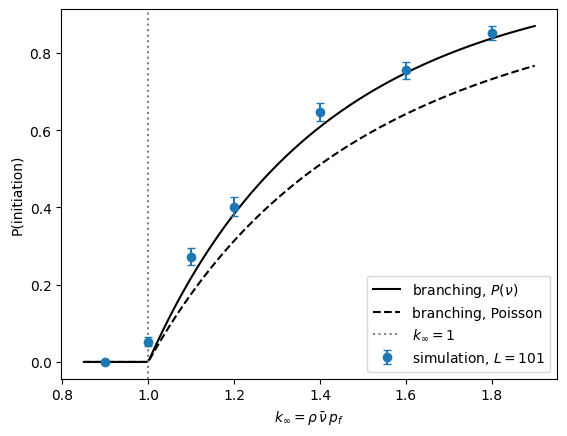

In [4]:
def q_initiate(a, offspring='nu'):
    """Probability that one fission starts a divergent chain. a = rho * p_f."""
    k = nu_bar * a
    if k <= 1:
        return 0.0
    if offspring == 'nu':
        G = lambda s: P_NU @ (1 - a + a * s) ** NU        # exact pgf: nu thinned by a
    else:
        G = lambda s: np.exp(-k * (1 - s))                # Poisson(k)
    return brentq(lambda q: 1 - q - G(1 - q), 1e-9, 1)

def initiated(N, n_c=500, t_c=60):
    return N.sum() >= n_c or (len(N) >= t_c and N[-1] > 0)

rng = np.random.default_rng(11)
L_init, n_runs = 101, 400
k_vals = np.array([0.9, 1.0, 1.1, 1.2, 1.4, 1.6, 1.8])
q_sim, q_err = [], []
for k in k_vals:
    x = [initiated(fission_generations(L_init, k / nu_bar, steps=60, n_cap=500, rng=rng))
         for _ in range(n_runs)]
    q_sim.append(np.mean(x)); q_err.append(np.sqrt(q_sim[-1] * (1 - q_sim[-1]) / n_runs))
    print(f"k={k:.1f}  sim={q_sim[-1]:.3f}±{q_err[-1]:.3f}  "
          f"P(nu)={q_initiate(k / nu_bar):.3f}  Poisson={q_initiate(k / nu_bar, 'poisson'):.3f}")

kk = np.linspace(0.85, 1.9, 200)
plt.plot(kk, [q_initiate(k / nu_bar) for k in kk], 'k-', label=r'branching, $P(\nu)$')
plt.plot(kk, [q_initiate(k / nu_bar, 'poisson') for k in kk], 'k--', label='branching, Poisson')
plt.errorbar(k_vals, q_sim, yerr=q_err, fmt='o', capsize=3, label=f'simulation, $L={L_init}$')
plt.axvline(1, color='grey', ls=':', label=r'$k_\infty = 1$')
plt.xlabel(r'$k_\infty = \rho\,\bar\nu\,p_f$'); plt.ylabel('P(initiation)'); plt.legend()
plt.savefig("6.3.png", dpi=200, bbox_inches='tight'); plt.show()

The plot is the key output and leads to the following interpretatiuons and conclusion:

**The result:**

1. **The threshold is at $k_\infty = 1$.** Below it no chain initiates. Above it the initiation probability rises from zero with a kink, the same transcritical signature as in 5.3.

2. **The $P(\nu)$ curve describes the data; the Poisson curve does not.** For $k_\infty \geq 1.2$ every point lies within $1.5\sigma$ of the $P(\nu)$ prediction, and $3.6$–$6.8\sigma$ above the Poisson one. Fission is under-dispersed, $\mathrm{Var}(\nu) \approx 1.2 < \bar\nu \approx 2.4$, so fewer chains die by chance in the first generations. The effect is large: at $k_\infty = 1.4$ the Poisson model underestimates $q$ by about 20%.

3. **There is no locality deficit.** In 5.3 the simulation fell *below* theory just above threshold, because attempts landed on spent traps and the effective $\kappa$ dropped. Here the points sit on or above the curve. Fuel is never depleted, so the process is linear and the branching-process prediction is exact in the mean, as anticipated in 6.1.

4. **The points at $k_\infty = 1.0$ and $1.1$ lie *above* theory.** This is an artifact of the finite cutoff $t_c = 60$, the mirror image of the $\rho = 0.2$ point in 5.3. At exactly $k = 1$ every chain dies eventually, but slowly: a critical branching process survives to generation $t$ with probability $\approx 2/(\sigma^2 t)$. Here the offspring variance is $\sigma^2 \approx 0.80$, which gives $\approx 0.04$ at $t_c = 60$, consistent with the measured $0.052 \pm 0.011$. The same slow extinction inflates the $k_\infty = 1.1$ point ($2.5\sigma$ above). Raising $t_c$ would push both down toward theory.

5. **Practical reading.** At $k_\infty = 1.2$ only about 40% of single fissions start a divergent chain. As with propagule pressure in 5.3, $n$ independent source fissions succeed with probability $1 - (1 - q)^n$. This is why reactors are started with a neutron source rather than relying on a single spontaneous fission.

**Summary.** Initiation is governed by the branching process with the real neutron multiplicity $P(\nu)$. The threshold is $k_\infty = 1$, and the spatial structure of the lattice plays no role, because without depletion nothing is lost to locality.

## 6.4) Critical size: how large must the system be?

Leakage gives $k_{\text{eff}}(L) < k_\infty$, and the critical size $L_c$ is where $k_{\text{eff}} = 1$. This has no analogue in Notebooks 3–5: there, a ball that would leave the lattice was redirected onto a cell inside it. Here a neutron that crosses the boundary is lost. A system with $k_\infty > 1$ that is too small loses too many neutrons through its surface to sustain a chain. This is the lattice version of a **critical mass**.

$k_{\text{eff}}(L)$ is computed in three ways, from approximate to exact:

**1. Diffusion theory.** Over many generations neutrons spread diffusively. The population settles into the fundamental mode of a bare square, $\cos(\pi x/L)\cos(\pi y/L)$, whose curvature is the buckling $B^2 = 2\pi^2/L^2$. Each generation a fraction $\approx M^2 B^2$ of neutrons is lost through the surface, which gives equation (1) of 6.1:
$$
k_{\text{eff}} = \frac{k_\infty}{1 + M^2 B^2}, \qquad M^2 = \frac{\langle r^2 \rangle}{4},
$$
where $\langle r^2 \rangle$ is the mean squared flight distance. Setting $k_{\text{eff}} = 1$:
$$
L_c = \pi\sqrt{\frac{2M^2}{k_\infty - 1}} .
$$
The flux does not actually vanish at the edge of the lattice but about one flight length beyond it. The standard correction replaces $L$ by $L + 2\delta$, with an extrapolation distance $\delta \approx 0.71\,M$ (the Milne-problem value, adapted here). Diffusion theory should fail when $L$ is only a few flight lengths.

**2. Fission matrix.** Let $K_{ij}$ be the expected number of fissions in cell $j$ caused by one fission in cell $i$. A vector of fissions per cell evolves as $\mathbf{n}_{t+1} = K\,\mathbf{n}_t$, so $k_{\text{eff}}$ is the dominant eigenvalue of $K$. Since $K$ is a convolution with the flight kernel, truncated at the boundary, it can be applied with an FFT and its eigenvalue found by **power iteration**, the same algorithm used by Monte Carlo reactor codes. This is the exact mean-field answer for the lattice, with no diffusion approximation.

**3. Simulation.** Start $n_0 = 2000$ fissions spread uniformly. After the higher spatial modes have decayed, $N_t \propto k_{\text{eff}}^t$, so
$$
k_{\text{eff}} \approx \left(N_{t_2}/N_{t_1}\right)^{1/(t_2 - t_1)},
$$
with $t_1 = 10$ and $t_2 = 24$.

Since the process is linear (6.2, 6.3), the simulation should agree with the fission matrix up to noise. Diffusion theory should agree only for large $L$.

**Code cell 1** defines the tools for computing $k_{\text{eff}}$:
- `flight_kernel` builds the probability $K(\Delta y, \Delta x)$ that a neutron lands at a given offset from its parent fission. The migration area $M^2 = \langle r^2\rangle/4$ is computed from it.
- `k_eff_matrix` computes the exact mean-field $k_{\text{eff}}$ by power iteration. It repeatedly convolves a fission distribution with $K$ (using an FFT), multiplies by $k_\infty$ and renormalises. Neutrons that fall outside the lattice are lost (leakage). The growth factor converges to the dominant eigenvalue of the fission matrix.
- `k_eff_diffusion` evaluates the diffusion-theory formula $k_\infty/(1 + M^2 B^2)$, with an optional extrapolation distance $\delta$.
- `k_eff_mc` estimates $k_{\text{eff}}$ from the lattice simulation. It starts 2000 uniformly spread fissions, measures the per-generation growth factor between generations 10 and 24, and averages over 20 runs.

In [5]:
from scipy.signal import fftconvolve

p_geo = 0.5

def flight_kernel(p_geo, tol=1e-8):
    """K[dy,dx] = probability a neutron lands at offset (dy,dx); also r^2 on the grid."""
    kmax = int(np.ceil(np.log(tol) / np.log(1 - p_geo)))
    yy, xx = np.mgrid[-kmax:kmax + 1, -kmax:kmax + 1]
    ch = np.maximum(abs(yy), abs(xx))
    K = np.where(ch > 0, p_geo * (1 - p_geo)**(ch - 1) / (8 * np.maximum(ch, 1)), 0.0)
    return K, yy**2 + xx**2

K_fl, r2 = flight_kernel(p_geo)
M2 = (K_fl * r2).sum() / 4                     # migration area: <r^2> = 4 M^2 in 2D
print(f"M^2 = {M2:.3f}  (migration length M = {np.sqrt(M2):.2f} cells)")

def k_eff_matrix(L, k_inf, iters=300):
    """Dominant eigenvalue of the fission matrix by power iteration (open boundary)."""
    v = np.ones((L, L))
    for _ in range(iters):
        w = k_inf * fftconvolve(v, K_fl, mode='same')   # mass falling outside = leakage
        k = w.sum() / v.sum()
        v = w / w.sum()
    return k, v

def k_eff_diffusion(L, k_inf, delta=0.0):
    B2 = 2 * np.pi**2 / (L + 2 * delta)**2      # buckling of a bare square
    return k_inf / (1 + M2 * B2)

def k_eff_mc(L, k_inf, n_rep=20, n0=2000, t1=10, t2=24, rng=None):
    """Generation estimator: growth factor of N(t) once the fundamental mode dominates."""
    g = []
    for _ in range(n_rep):
        N = fission_generations(L, k_inf / nu_bar, n0=n0, steps=t2 + 1, rng=rng)
        if len(N) > t2 and N[t1] > 0 and N[t2] > 0:
            g.append((N[t2] / N[t1]) ** (1 / (t2 - t1)))
    return np.mean(g), np.std(g, ddof=1) / np.sqrt(len(g))

M^2 = 2.042  (migration length M = 1.43 cells)


**Code cell 2** runs the measurements and plots them:
- For $k_\infty = 1.3$, it computes $k_{\text{eff}}(L)$ with all three methods and prints a comparison.
- For a range of $k_\infty$, it finds the critical size $L_c$ where the fission-matrix $k_{\text{eff}}$ crosses 1 (by linear interpolation), and compares it with the diffusion prediction $L_c = \pi\sqrt{2M^2/(k_\infty - 1)}$, with and without $\delta$.
- Left plot: $k_{\text{eff}}$ against $L$. Right plot: $L_c$ against $k_\infty$, on a log scale.

L= 6  MC 0.8154±0.0061   matrix 0.8203   diffusion 0.6134   diffusion+delta 0.7999
L= 8  MC 0.9486±0.0025   matrix 0.9515   diffusion 0.7977   diffusion+delta 0.9281
L=10  MC 1.0370±0.0007   matrix 1.0369   diffusion 0.9266   diffusion+delta 1.0168
L=14  MC 1.1363±0.0007   matrix 1.1361   diffusion 1.0783   diffusion+delta 1.1237
L=20  MC 1.2051±0.0003   matrix 1.2063   diffusion 1.1810   diffusion+delta 1.2003
L=30  MC 1.2489±0.0004   matrix 1.2531   diffusion 1.2443   diffusion+delta 1.2509
k_inf=1.05  L_c matrix=25.60  diffusion=28.39  diffusion+delta=26.36
k_inf=1.10  L_c matrix=17.33  diffusion=20.08  diffusion+delta=18.05
k_inf=1.20  L_c matrix=11.56  diffusion=14.20  diffusion+delta=12.17
k_inf=1.30  L_c matrix=9.04  diffusion=11.59  diffusion+delta=9.56
k_inf=1.50  L_c matrix=6.63  diffusion=8.98  diffusion+delta=6.95
k_inf=1.80  L_c matrix=4.96  diffusion=7.10  diffusion+delta=5.07
k_inf=2.20  L_c matrix=3.90  diffusion=5.80  diffusion+delta=3.77


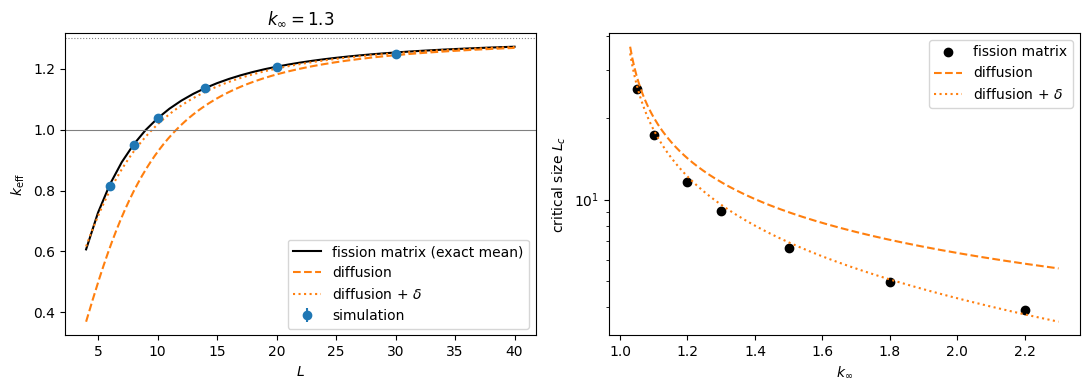

In [7]:
k_inf = 1.3
delta = 0.71 * np.sqrt(M2)                       # extrapolation distance
rng = np.random.default_rng(12)

# k_eff(L) at fixed k_inf
L_mat = np.arange(4, 41)
k_mat = np.array([k_eff_matrix(L, k_inf)[0] for L in L_mat])
L_mc = np.array([6, 8, 10, 14, 20, 30])
k_mc = np.array([k_eff_mc(L, k_inf, rng=rng) for L in L_mc])
for L, (k, dk) in zip(L_mc, k_mc):
    print(f"L={L:2d}  MC {k:.4f}±{dk:.4f}   matrix {k_eff_matrix(L, k_inf)[0]:.4f}   "
          f"diffusion {k_eff_diffusion(L, k_inf):.4f}   diffusion+delta {k_eff_diffusion(L, k_inf, delta):.4f}")

# critical size L_c(k_inf)
def L_crit_matrix(k_inf):
    Ls = np.arange(2, 120)
    ks = np.array([k_eff_matrix(L, k_inf, iters=150)[0] for L in Ls])
    j = np.argmax(ks > 1)
    return Ls[j-1] + (1 - ks[j-1]) / (ks[j] - ks[j-1])           # linear interpolation

L_crit_diff = lambda k_inf, d=0.0: np.pi * np.sqrt(2 * M2 / (k_inf - 1)) - 2 * d

kinf_vals = np.array([1.05, 1.1, 1.2, 1.3, 1.5, 1.8, 2.2])
Lc_mat = np.array([L_crit_matrix(k) for k in kinf_vals])
for k, Lc in zip(kinf_vals, Lc_mat):
    print(f"k_inf={k:.2f}  L_c matrix={Lc:.2f}  diffusion={L_crit_diff(k):.2f}  "
          f"diffusion+delta={L_crit_diff(k, delta):.2f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
LL = np.linspace(4, 40, 200)
ax[0].plot(L_mat, k_mat, 'k-', label='fission matrix (exact mean)')
ax[0].plot(LL, k_eff_diffusion(LL, k_inf), 'C1--', label='diffusion')
ax[0].plot(LL, k_eff_diffusion(LL, k_inf, delta), 'C1:', label=r'diffusion + $\delta$')
ax[0].errorbar(L_mc, k_mc[:, 0], yerr=k_mc[:, 1], fmt='o', color='C0', label='simulation')
ax[0].axhline(1, color='grey', lw=0.8); ax[0].axhline(k_inf, color='grey', ls=':', lw=0.8)
ax[0].set_xlabel('$L$'); ax[0].set_ylabel(r'$k_{\rm eff}$'); ax[0].set_title(fr'$k_\infty={k_inf}$')
ax[0].legend()

kk = np.linspace(1.03, 2.3, 200)
ax[1].plot(kinf_vals, Lc_mat, 'ko', label='fission matrix')
ax[1].plot(kk, L_crit_diff(kk), 'C1--', label='diffusion')
ax[1].plot(kk, L_crit_diff(kk, delta), 'C1:', label=r'diffusion + $\delta$')
ax[1].set_xlabel(r'$k_\infty$'); ax[1].set_ylabel('critical size $L_c$')
ax[1].set_yscale('log'); ax[1].legend()
plt.tight_layout(); fig.savefig("6.4).png", dpi=200, bbox_inches='tight'); plt.show()

**The result:**

*Left ($k_\infty = 1.3$).*
- The simulation lies on the fission-matrix curve for $L \leq 20$, within about $1\sigma$. Because the model is linear, the mean of the simulation is exactly the dominant eigenvalue of the fission matrix. This is the third confirmation of linearity, after 6.2 and 6.3.
- At $L = 30$ the simulation is slightly low ($1.2489$ against $1.2531$). This is a limitation of the estimator, not of the model. The uniform starting distribution contains higher spatial modes, which decay as $(k_2/k_1)^t$. For large $L$, $k_2/k_1 \to 1$, so after $t_1 = 10$ generations the fundamental mode has not fully taken over. A later $t_1$, or starting from the eigenvector returned by `k_eff_matrix`, would remove the bias.
- Plain diffusion underestimates $k_{\text{eff}}$ badly for small systems: $0.61$ against $0.82$ at $L = 6$. With the extrapolation distance $\delta \approx 0.71\,M$ it is within $0.02$ of the exact value for $L \geq 6$.
- $k_{\text{eff}} = 1$ at $L_c \approx 9$. A material with $k_\infty = 1.3$ cannot sustain a chain if the system is smaller than this, even though every fission produces on average 1.3 new ones in an infinite medium.

*Right (critical size).*
- $L_c$ diverges as $k_\infty \to 1$, following $L_c \propto (k_\infty - 1)^{-1/2}$: a barely supercritical material needs an arbitrarily large system.
- Plain diffusion overestimates $L_c$ by about two cells at every $k_\infty$. This is a constant offset, so it matters most for small systems. Diffusion $+\,\delta$ agrees with the fission matrix to within about $0.5$ cells for $k_\infty \leq 1.8$, which shows that the error is a surface effect of the size of one flight length.
- At $k_\infty = 2.2$, diffusion $+\,\delta$ starts to *underestimate* $L_c$. Here $L_c \approx 4$ cells, less than three migration lengths ($M \approx 1.4$), so the system is too small for diffusion theory to apply at all.

**Interpretation.** Leakage turns the infinite-medium threshold $k_\infty = 1$ into a size threshold $k_{\text{eff}}(L) = 1$. This is the origin of the critical mass: a sphere of ${}^{235}\mathrm{U}$ is supercritical only above a certain size, because below it too many neutrons escape through the surface. In population dynamics the same eigenvalue problem gives the minimum habitat size for a dispersing population, the KISS problem (Kierstead–Slobodkin–Skellam): a patch must be large enough that reproduction outweighs losses through its edge, this serves as a reminder that this modleling of nuclear fission shares the same theoreticla framework as population dynamics in notebook 5.

## 6.5) Delayed neutrons 
This section will also explain why reactors can be controlled, including prompt criticality.

So far every neutron was **prompt**: emitted at the fission and causing the next fission one generation later. In a thermal reactor one generation lasts $\Lambda \sim 10^{-4}$ s. A reactor at $k = 1.001$ would then grow by a factor $e$ every $1/(k-1) = 1000$ generations, about $0.1$ s, which is too fast for any mechanical control system.

A fraction $\beta \approx 0.0065$ of the neutrons from ${}^{235}\mathrm{U}$ fission are **delayed**. They are emitted by the decay of certain fission products ("precursors"), with a mean delay of order $10$ s. Small as $\beta$ is, it changes the timescale completely.

**Mean-field map.** Let $n_t$ be the fissions in generation $t$ and $C_t$ the delayed fissions still pending. A fraction $1-\beta$ of the offspring appear in the next generation. The rest join the pending pool, which releases a fraction $\lambda$ per generation:
$$
\begin{aligned}
n_{t+1} &= k(1-\beta)\,n_t + \lambda\left(C_t + k\beta\,n_t\right) \\
C_{t+1} &= (1-\lambda)\left(C_t + k\beta\,n_t\right)
\end{aligned} \tag{2}
$$
The long-term growth factor per generation, $\omega$, is the dominant eigenvalue of this $2\times 2$ linear map. Three regimes follow:
- **$k < 1$, subcritical:** $\omega < 1$, the population decays.
- **$1 < k < 1/(1-\beta)$, delayed-supercritical:** the prompt neutrons alone give $k(1-\beta) < 1$, so the chain grows only by waiting for delayed neutrons. Growth is slow, set by $\lambda$. To leading order, with reactivity $\varrho = (k-1)/k$,
$$
\omega - 1 \approx \frac{\lambda\,\varrho}{\beta - \varrho} .
$$
- **$k > 1/(1-\beta)$, prompt-supercritical:** prompt neutrons alone sustain a growing chain, and the delayed neutrons no longer slow it down.

Reactors are always operated in the delayed-supercritical window, $\varrho < \beta$. With realistic values ($\Lambda \approx 10^{-4}$ s, $\lambda \approx 0.08\ \mathrm{s}^{-1}$) and $\varrho = 0.001$, the $e$-folding time grows from $0.1$ s (prompt only) to about $70$ s. That is slow enough to control with absorber rods.

**Prompt jump.** If $k$ is suddenly changed from $1$ to $k_1$ (a control rod is moved), the prompt neutrons adjust within a few generations, while the pending pool has not changed yet. The population quickly jumps to a new level and then evolves slowly at the rate $\omega$. Holding $C$ at its old equilibrium value in (2) gives the jump
$$
\frac{n_+}{n_0} = \frac{(1-\lambda)\,\beta}{1 - k_1(1-\beta+\lambda\beta)} ,
$$
which reduces to the textbook $\beta/(\beta - \varrho)$ as $\lambda \to 0$.

**Toy values.** Real delays span about $10^5$ generations and cannot be simulated. I use $\beta = 0.1$ and $\lambda = 0.02$. These are exaggerated, but they preserve the ordering $\lambda \ll \beta \ll 1$, and every formula above is the same.

**Measurement.** Start a critical system ($k = 1$) at equilibrium, with $n_0 = 2000$ fissions per generation and the matching pending pool $C_0 = (1-\lambda)\beta n_0/\lambda$. At $t = 20$, step $k$ to $0.98$, $1.03$ or $1.15$ (the last is above prompt critical, $1/(1-\beta) = 1.11$). A periodic lattice is used, so there is no leakage and $k = k_\infty$.

The following code cell defines the mean-field kinetics and the growth rate:
- `point_kinetics` iterates map (2). Each generation, a fraction $1-\beta$ of the new fissions appear in the next generation, the rest join the pending pool $C$, and the pool releases a fraction $\lambda$ per generation. $k$ can be a constant or a function of time, which is used for the step change in cell 2.
- `growth_factor` writes map (2) as a $2\times 2$ matrix acting on $(n, C)$ and returns its dominant eigenvalue $\omega$, the long-term growth factor per generation.
- The loop prints $\omega - 1$ for several $k$, next to the all-prompt value $k - 1$.
- The plot shows $\omega - 1$ against $k$ with and without delayed neutrons, and marks the critical point $k = 1$ and the prompt-critical point $k = 1/(1-\beta)$.

k=0.98  omega-1 = -0.0030   prompt only: k-1 = -0.0200
k=1.00  omega-1 = +0.0000   prompt only: k-1 = +0.0000
k=1.03  omega-1 = +0.0062   prompt only: k-1 = +0.0300
k=1.08  omega-1 = +0.0232   prompt only: k-1 = +0.0800
k=1.11  omega-1 = +0.0384   prompt only: k-1 = +0.1100
k=1.15  omega-1 = +0.0641   prompt only: k-1 = +0.1500


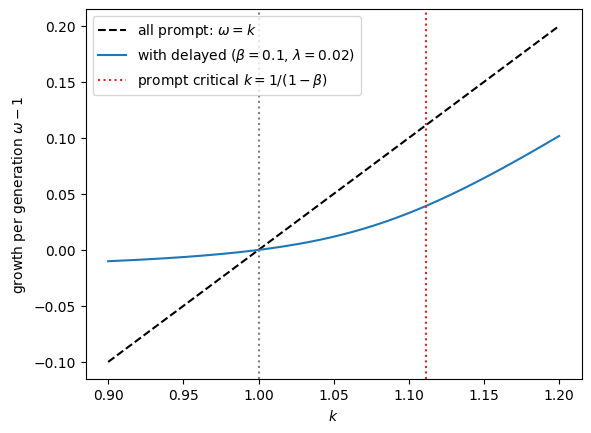

In [ ]:
beta, lam = 0.1, 0.02          # toy values; U-235: beta = 0.0065, lam ~ 1e-5 per generation

def point_kinetics(k, beta, lam, n0, C0, steps):
    """Mean-field map (2). k may be a number or a function of t."""
    n, C, out = n0, C0, [n0]
    for t in range(steps):
        kt = k(t) if callable(k) else k
        n, C = kt * (1 - beta) * n + lam * (C + kt * beta * n), (1 - lam) * (C + kt * beta * n)
        out.append(n)
    return np.array(out)

def growth_factor(k, beta, lam):
    """Dominant eigenvalue omega of map (2)."""
    A = np.array([[k * (1 - beta + lam * beta), lam],
                  [(1 - lam) * k * beta,       1 - lam]])
    return np.max(np.abs(np.linalg.eigvals(A)))

for k in [0.98, 1.0, 1.03, 1.08, 1.11, 1.15]:
    print(f"k={k:.2f}  omega-1 = {growth_factor(k, beta, lam) - 1:+.4f}   prompt only: k-1 = {k - 1:+.4f}")

kk = np.linspace(0.9, 1.2, 300)
omega = np.array([growth_factor(k, beta, lam) for k in kk])
plt.plot(kk, kk - 1, 'k--', label=r'all prompt: $\omega = k$')
plt.plot(kk, omega - 1, 'C0-', label=fr'with delayed ($\beta={beta}$, $\lambda={lam}$)')
plt.axvline(1, color='grey', ls=':')
plt.axvline(1 / (1 - beta), color='C3', ls=':', label=r'prompt critical $k = 1/(1-\beta)$')
plt.xlabel('$k$'); plt.ylabel(r'growth per generation $\omega - 1$'); plt.legend()
plt.savefig("6.5).png", dpi=200, bbox_inches='tight'); plt.show()

**The result (growth rate):**

1. **The critical point is unchanged.** Both curves cross zero at $k = 1$. Delayed neutrons do not change whether the population grows, only how fast.

2. **Delayed-supercritical window ($1 < k < 1/(1-\beta)$): growth is strongly slowed.** At $k = 1.03$, $\omega - 1 = 0.0062$, against $0.03$ if all neutrons were prompt. The $e$-folding time grows from $\approx 33$ to $\approx 160$ generations. The curve is flat near $k = 1$ because the chain can only grow as fast as the pending pool releases neutrons, at a rate set by $\lambda$, not by the generation time.

3. **Above prompt critical ($k > 1.11$): the slowing is lost.** Here $k(1-\beta) > 1$, so the prompt neutrons alone sustain a growing chain. The curve steepens towards the all-prompt line, with slope approaching $1-\beta$. With the toy values the change is gradual, because $\lambda = 0.02$ is not very small compared with $\beta = 0.1$. With realistic values ($\lambda/\beta \sim 10^{-3}$) the change at $k = 1/(1-\beta)$ becomes a sharp kink, from growth on a timescale of seconds to minutes to growth on a timescale of $10^{-4}$ s.

4. **Subcritical side: decay cannot be faster than the pool drains.** For all-prompt neutrons the population decays at rate $1 - k$, which can be arbitrarily fast. With delayed neutrons $\omega - 1$ levels off: as $k \to 0$, $\omega \to 1 - \lambda$, so the population can never fall faster than the pending pool drains. In a real reactor this means that even after an emergency shutdown the power falls with a period of about $80$ s, set by the longest-lived precursor.

**Interpretation.** Reactor control works because operation is confined to the window $1 < k < 1/(1-\beta)$, where the response time is set by the slow delayed neutrons. A fraction $\beta = 0.65\%$ of the neutrons is enough to stretch the timescale by about three orders of magnitude, which makes a mechanical control system possible.

## 6.6) Conclusion

Notebook 5 showed that the mousetrap cascade is a population model. This notebook shows that the same structure describes a **nuclear chain reaction**, with neutrons as offspring, $k_\infty = \rho\,\bar\nu\,p_f$ in place of $\rho\kappa$, and three physical changes: fuel is not depleted, neutrons can leak through the boundary, and a fraction $\beta$ of them is delayed. The three questions set in 6.1 have the following answers.

| Question | Mean-field prediction | Lattice result |
|---|---|---|
| **Initiation** (6.3) | possible iff $k_\infty > 1$; probability $q$ from the branching process with $P(\nu)$ | threshold at $k_\infty = 1$; for $k_\infty \geq 1.2$ the simulation follows the $P(\nu)$ curve within $1.5\sigma$ and lies $3.6$–$6.8\sigma$ above Poisson; no locality deficit |
| **Critical size** (6.4) | $k_{\text{eff}}(L) = 1$ at $L_c = \pi\sqrt{2M^2/(k_\infty - 1)}$ (diffusion); exact value from the fission matrix | simulation matches the fission-matrix eigenvalue within $\approx 1\sigma$ for $L \leq 20$; diffusion overestimates $L_c$ by $\approx 2$ cells, diffusion $+\,\delta$ is within $0.5$ cells for $k_\infty \leq 1.8$ |
| **Kinetics and control** (6.5) | critical at $k = 1$; slow growth for $1 < k < 1/(1-\beta)$; prompt jump $n_+/n_0 = (1-\lambda)\beta/[1 - k_1(1-\beta+\lambda\beta)]$ | growth slowed about fivefold at $k = 1.03$; prompt jump to the predicted level after a step in $k$; fast growth above prompt critical |

**Main finding: linearity.** In Notebooks 3–5 mean-field theory was systematically off because of *locality*: attempts landed on spent traps, lowering the effective $\kappa$. Here fuel is never depleted, neutrons do not compete for targets, and the process is a linear branching random walk. As a result:
- the mean grows exactly as $k^t$ (6.2);
- the initiation probability shows none of the deficit seen in 5.3 (6.3);
- the simulated $k_{\text{eff}}$ equals the fission-matrix eigenvalue (6.4);
- the simulated kinetics follows the mean-field map (6.5).

This confirms the explanation given in Notebook 5: the discrepancies there came from depletion, a nonlinearity, not from the lattice itself.

**What mean-field theory still misses.** Fluctuations. Mean-field theory predicts the mean exactly but says nothing about individual chains. Chains die out above threshold (6.3), and near $k = 1$ the population wanders with slow, correlated fluctuations (6.5). Spatial structure enters only through the boundary. It is captured exactly by the fission matrix, and approximately by diffusion theory once the system is many flight lengths across.

**Links to the earlier notebooks.**
- The initiation probability is the invasion probability of 5.3, and obeys the same equation as the final-size equation of Notebook 3.
- The critical size is the minimum habitat size of spatial ecology (the KISS problem).
- The delayed neutrons are a reservoir with slow release, the role played by the spent pool and $p_{\text{regen}}$ in 5.4. In both cases a slow reservoir sets the timescale of the dynamics.

**Limitations.**
- The model is two-dimensional, with flights on Chebyshev rings rather than isotropic in Euclidean space.
- Single-speed neutrons: no slowing down, no energy dependence of the cross-sections.
- Toy values $\beta = 0.1$, $\lambda = 0.02$, and one delayed group instead of the six used in reactor physics.
- The values of $P(\nu)$ are approximate.
- The $k_{\text{eff}}$ estimator is biased for large $L$, because higher spatial modes have not decayed by $t_1 = 10$.
- Only 3 runs per step change in 6.5.

**Next steps.**
1. Restore depletion (the explosive regime) and compare the yield with the final-size equation $F = 1 - e^{-kF}$.
2. Add a reflector, a non-fissile border that scatters neutrons back, and measure how much it reduces $L_c$.
3. Make $k$ depend on $N_t$ (temperature feedback) and look for self-regulation, analogous to $s^* \approx 1/\kappa$ in 5.5.
4. Start the $k_{\text{eff}}$ estimator from the fission-matrix eigenvector, to remove the large-$L$ bias.

None of these *next steps* will be attempted in this or any other notepooks in this repository, but it is the natural continuation of the work conducted here.